# Modelo KNN para predecir el ICVU

* Tipo: supervisado, regresión (variable objetivo: nivel ICVU 2025 codificado 1 = Bajo … 4 = Alto, porque la CChC ya no publica el puntaje numérico; la predicción se redondea al nivel más cercano)
* Modelo: KNN (`KNeighborsRegressor`)
* Unidad de análisis: **comuna** (una fila por comuna, generada por `data_obtain_comunas.ipynb`)

v1.0 · 18-10-2026

**Correcciones respecto de la versión v0.0**

| Problema | Corrección |
|---|---|
| `dataset_src = "./"` (carpeta, no archivo) | Apunta a `dataset_comunas.csv` y verifica que exista y tenga ICVU |
| `X` incluía texto (nombre de comuna) → `StandardScaler` falla | Solo columnas numéricas, elegidas por grupo (`FEATURE_SET`) |
| NaN → KNN falla | `SimpleImputer` dentro del Pipeline |
| Conteos muy sesgados (pocas comunas concentran todo) | `log1p` dentro del Pipeline |
| Una sola separación 80/20 con ~30 comunas = ~7 de prueba, resultado muy inestable | **Validación cruzada anidada repetida** (5 × 10): la búsqueda de K se hace dentro de cada pliegue, sin mirar los datos de prueba |
| Sin referencia | Se compara contra `DummyRegressor` (predice siempre el promedio) |
| `K` hasta 20 aunque haya pocas filas | El rango de K se ajusta al tamaño del entrenamiento |
| Import duplicado; `pip install --upgrade` (podía romper el entorno) | Import eliminado; instalación simple sin `--upgrade` |

### Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [ ]:
%pip install -q pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import KFold, RepeatedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, root_mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

### Parámetros

In [ ]:
DEBUG = True
SEMILLA = 42

DATASET = "dataset_comunas.csv"   # salida de data_obtain_comunas.ipynb (con ICVU unido)
# La CChC ya no publica el puntaje numérico, solo el nivel -> objetivo ordinal 1 (Bajo) .. 4 (Alto).
# Si consigues el puntaje numérico, agrégalo como columna ICVU y usa OBJETIVO = "ICVU".
OBJETIVO = "ICVU_nivel"
ES_ORDINAL = OBJETIVO == "ICVU_nivel"   # agrega la métrica "acierto de nivel"
ID_COLS = ["comuna"]

# Qué variables usa el modelo. KNN empeora con muchas variables (todas pesan igual en la distancia),
# así que por defecto se usan los totales por categoría + % de área.
#   "categoria" -> dens_cat_* + pct_area_*            (~12 variables)
#   "tipo"      -> dens_<tipo> + pct_area_*           (~39 variables)
#   "habitante" -> x10k_cat_* + pct_area_* + hab_km2  (por 10.000 hab; requiere poblacion_comunas.csv)
#   "habitante_tipo" -> x10k_<tipo> + pct_area_* + hab_km2
#   o una lista explícita de columnas
# Elegido "habitante_tipo": con los datos reales (42 comunas, CV 5x10) fue el de menor error
#   habitante_tipo RMSE 0.86 · tipo 0.98 · habitante 1.07 · categoria 1.09 · baseline 1.14
# Además, las variables por habitante evitan el sesgo de las comunas con mucha superficie
# rural (Lo Barnechea, Colina, Melipilla...), cuyas densidades por km² salen artificialmente bajas.
FEATURE_SET = "habitante_tipo"

USAR_LOG = True        # log1p a las variables (son densidades >= 0 y muy sesgadas)

# Validación cruzada
CV_EXTERNA_PLIEGUES = 5
CV_EXTERNA_REPETICIONES = 10
CV_INTERNA_PLIEGUES = 5
K_MAX = 20

GUARDAR_MODELO = "modelo_knn_icvu.joblib"

### Cargar dataset

In [ ]:
if not Path(DATASET).exists():
    raise FileNotFoundError(f"No existe {DATASET}. Ejecutar antes data_obtain_comunas.ipynb")

df = pd.read_csv(DATASET)
if OBJETIVO not in df.columns:
    raise KeyError(f"El dataset no tiene la columna {OBJETIVO}. Completar icvu_comunas.csv "
                   f"y volver a ejecutar la sección 'Unir ICVU' de data_obtain_comunas.ipynb")

sin_y = df[OBJETIVO].isna()
if sin_y.any():
    print("Se excluyen (sin ICVU):", df.loc[sin_y, "comuna"].tolist())
df = df[~sin_y].reset_index(drop=True)

if DEBUG:
    print(df.shape)
    print(df[OBJETIVO].describe())

(42, 127)
count    42.000000
mean      2.285714
std       1.132356
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       4.000000
Name: ICVU_nivel, dtype: float64


### Selección de variables

In [ ]:
def seleccionar_features(df, feature_set):
    if isinstance(feature_set, (list, tuple)):
        cols = list(feature_set)
    else:
        prefijos = {"categoria": ["dens_cat_"],
                    "tipo": ["dens_"],
                    "habitante": ["x10k_cat_"],
                    "habitante_tipo": ["x10k_"]}[feature_set]
        cols = [c for c in df.columns if any(c.startswith(p) for p in prefijos)]
        if feature_set == "tipo":
            cols = [c for c in cols if not c.startswith("dens_cat_")]
        if feature_set == "habitante_tipo":
            cols = [c for c in cols if not c.startswith("x10k_cat_")]
        cols += [c for c in df.columns if c.startswith("pct_area_")]
        if feature_set.startswith("habitante"):
            cols += ["hab_km2"]
        if not cols:
            raise ValueError(f"No hay columnas para FEATURE_SET={feature_set!r} "
                             f"(¿falta poblacion_comunas.csv para las variables por habitante?)")
    cols = [c for c in cols if c not in ID_COLS + [OBJETIVO]
            and pd.api.types.is_numeric_dtype(df[c])]
    # Variables constantes (p. ej. 0 en todas las comunas) no aportan a la distancia
    constantes = [c for c in cols if df[c].nunique(dropna=True) <= 1]
    if constantes and DEBUG:
        print("Se descartan por constantes:", constantes)
    return [c for c in cols if c not in constantes]


features = seleccionar_features(df, FEATURE_SET)
X = df[features]
y = df[OBJETIVO]
n = len(df)

print(f"{n} comunas, {len(features)} variables")
if n < 10:
    raise ValueError("Muy pocas comunas para entrenar y evaluar. Agregar comunas en data_obtain_comunas.ipynb")
if DEBUG:
    print(features)
    print(X.isna().sum()[X.isna().sum() > 0])

42 comunas, 40 variables
['x10k_Hospital', 'x10k_Clinica', 'x10k_Centro_salud', 'x10k_Consultorio', 'x10k_Farmacia', 'x10k_Parque', 'x10k_Mall', 'x10k_Restaurante', 'x10k_Museo', 'x10k_Biblioteca', 'x10k_Teatro', 'x10k_Bomberos', 'x10k_Comisaria', 'x10k_Colegio', 'x10k_Jardin_infantil', 'x10k_Universidad', 'x10k_Supermercado', 'x10k_Banco', 'x10k_Feria', 'x10k_Almacen', 'x10k_Metro_estacion', 'x10k_Tren_estacion', 'x10k_Metro_entrada', 'x10k_Paradero_bus', 'x10k_Paradero_plataforma', 'x10k_Terminal_bus', 'x10k_Vertedero', 'x10k_Planta_residuos', 'x10k_Industrial', 'x10k_Fabrica', 'x10k_Botilleria', 'x10k_Bar_pub', 'x10k_Sitio_eriazo', 'x10k_Suelo_desnudo', 'pct_area_Parque', 'pct_area_Industrial', 'pct_area_Vertedero', 'pct_area_Sitio_eriazo', 'pct_area_Suelo_desnudo', 'hab_km2']
Series([], dtype: int64)


### Modelo

In [ ]:
def crear_pipeline():
    pasos = []
    if USAR_LOG:
        pasos.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    pasos += [
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),   # necesario para KNN
        ("knn", KNeighborsRegressor()),
    ]
    return Pipeline(pasos)


# K no puede superar el tamaño del entrenamiento dentro de la CV interna
n_train_interno = int(n * (1 - 1 / CV_EXTERNA_PLIEGUES) * (1 - 1 / CV_INTERNA_PLIEGUES))
k_max = max(1, min(K_MAX, n_train_interno))

param_grid = {
    "knn__n_neighbors": list(range(1, k_max + 1)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],    # Manhattan vs Euclidiana
}


def crear_busqueda():
    return GridSearchCV(crear_pipeline(), param_grid,
                        cv=KFold(CV_INTERNA_PLIEGUES, shuffle=True, random_state=SEMILLA),
                        scoring="neg_root_mean_squared_error", n_jobs=-1)

print(f"K entre 1 y {k_max}")

K entre 1 y 20


### Evaluación: validación cruzada anidada repetida

En cada uno de los 5 × 10 = 50 pliegues externos: se busca el mejor K **solo con el entrenamiento** del pliegue y se mide el error en las comunas que quedaron fuera. Así la métrica no está inflada por haber elegido K mirando los datos de prueba.

In [ ]:
def a_nivel(pred):
    # predicción continua -> nivel 1..4 más cercano
    return np.clip(np.rint(pred), 1, 4)


def metricas(y_true, y_pred):
    m = {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }
    if ES_ORDINAL:
        dif = np.abs(a_nivel(y_pred) - np.asarray(y_true))
        m["Acierto_nivel"] = np.mean(dif == 0)       # nivel exacto
        m["Acierto_±1"] = np.mean(dif <= 1)          # a lo más un nivel de diferencia
    return m


cv_ext = RepeatedKFold(n_splits=CV_EXTERNA_PLIEGUES, n_repeats=CV_EXTERNA_REPETICIONES,
                       random_state=SEMILLA)
filas, mejores = [], []
for tr, te in cv_ext.split(X):
    busq = crear_busqueda().fit(X.iloc[tr], y.iloc[tr])
    base = DummyRegressor(strategy="mean").fit(X.iloc[tr], y.iloc[tr])
    filas.append({"modelo": "KNN", **metricas(y.iloc[te], busq.predict(X.iloc[te]))})
    filas.append({"modelo": "Baseline (promedio)", **metricas(y.iloc[te], base.predict(X.iloc[te]))})
    mejores.append(busq.best_params_)

res = pd.DataFrame(filas)
resumen = res.groupby("modelo").agg(["mean", "std"]).round(3)
print(resumen.to_string())

print("\nParámetros elegidos con más frecuencia en los pliegues:")
print(pd.DataFrame(mejores).value_counts().head(5).to_string())

                       MSE          RMSE          MAE          MAPE            R2        Acierto_nivel        Acierto_±1       
                      mean    std   mean   std   mean    std   mean    std   mean    std          mean    std       mean    std
modelo                                                                                                                         
Baseline (promedio)  1.326  0.425  1.135  0.20  1.000  0.210  0.591  0.205 -0.415  1.428         0.304  0.155      0.769  0.146
KNN                  0.782  0.348  0.864  0.19  0.693  0.164  0.394  0.139  0.130  0.819         0.411  0.165      0.917  0.081

Parámetros elegidos con más frecuencia en los pliegues:
knn__n_neighbors  knn__p  knn__weights
2                 1       distance        11
6                 2       distance         5
3                 1       distance         5
2                 1       uniform          4
3                 2       distance         3


### Predicción fuera de muestra por comuna
Cada comuna se predice con un modelo que no la vio al entrenar.

Matriz real (filas) vs predicho (columnas), 1=Bajo .. 4=Alto:
nivel_pred  1  2  3  4
ICVU_real             
1           3  8  2  0
2           3  7  3  0
3           0  4  2  1
4           0  3  4  2 

             comuna  ICVU_real  ICVU_pred  error  nivel_pred
         San Miguel          4       1.84  -2.16           2
           Lo Prado          1       3.01   2.01           3
          Talagante          1       2.80   1.80           3
       Lo Barnechea          4       2.49  -1.51           2
         Huechuraba          4       2.49  -1.51           2
      Padre Hurtado          1       2.18   1.18           2
          Peñalolén          3       1.99  -1.01           2
           Conchalí          1       2.00   1.00           2
          Cerrillos          2       1.00  -1.00           1
          Melipilla          1       1.99   0.99           2
              Ñuñoa          4       3.01  -0.99           3
             Colina          3       2.04  -0.96           2
     

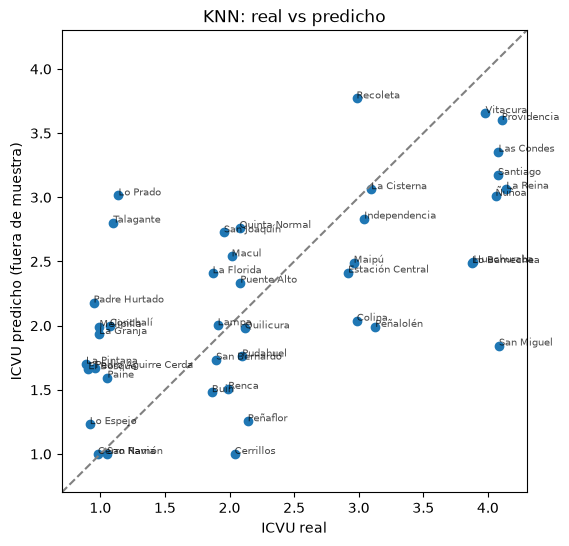

In [ ]:
y_oof = cross_val_predict(crear_busqueda(), X, y,
                          cv=KFold(CV_EXTERNA_PLIEGUES, shuffle=True, random_state=SEMILLA))
pred = df[ID_COLS].assign(ICVU_real=y, ICVU_pred=y_oof, error=y_oof - y)
if ES_ORDINAL:
    pred["nivel_pred"] = a_nivel(y_oof).astype(int)
    print("Matriz real (filas) vs predicho (columnas), 1=Bajo .. 4=Alto:")
    print(pd.crosstab(pred["ICVU_real"], pred["nivel_pred"]), "\n")
print(pred.sort_values("error", key=abs, ascending=False).round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 6))
# pequeño desplazamiento horizontal para que no se tapen las comunas del mismo nivel
x_plot = y + (np.random.default_rng(SEMILLA).uniform(-0.15, 0.15, len(y)) if ES_ORDINAL else 0)
ax.scatter(x_plot, y_oof)
for xi, (_, r) in zip(x_plot, pred.iterrows()):
    ax.annotate(r[ID_COLS[0]], (xi, r.ICVU_pred), fontsize=7, alpha=0.7)
margen = 0.1 * (y.max() - y.min())
lims = [min(y.min(), y_oof.min()) - margen, max(y.max(), y_oof.max()) + margen]
ax.plot(lims, lims, linestyle="--", color="gray")
ax.set(xlim=lims, ylim=lims, xlabel="ICVU real", ylabel="ICVU predicho (fuera de muestra)",
       title="KNN: real vs predicho")
plt.show()

### Modelo final (entrenado con todas las comunas)

In [ ]:
final = crear_busqueda().fit(X, y)
print("Mejores parámetros:", final.best_params_)
print(f"RMSE CV interno: {-final.best_score_:.3f}")

if GUARDAR_MODELO:
    joblib.dump({"modelo": final.best_estimator_, "features": features}, GUARDAR_MODELO)
    print("Guardado en", GUARDAR_MODELO)

Mejores parámetros: {'knn__n_neighbors': 2, 'knn__p': 1, 'knn__weights': 'distance'}
RMSE CV interno: 0.768
Guardado en modelo_knn_icvu.joblib


### (Opcional) Comparar conjuntos de variables

In [ ]:
if DEBUG:
    opciones = ["categoria", "tipo"] + (["habitante", "habitante_tipo"]
                                        if any(c.startswith("x10k_") for c in df.columns) else [])
    comp = []
    for fs in opciones:
        cols = seleccionar_features(df, fs)
        Xi = df[cols]
        rmse = []
        for tr, te in RepeatedKFold(n_splits=CV_EXTERNA_PLIEGUES, n_repeats=3, random_state=SEMILLA).split(Xi):
            b = crear_busqueda().fit(Xi.iloc[tr], y.iloc[tr])
            rmse.append(root_mean_squared_error(y.iloc[te], b.predict(Xi.iloc[te])))
        comp.append({"FEATURE_SET": fs, "n_variables": len(cols), "RMSE_medio": np.mean(rmse)})
    print(pd.DataFrame(comp).round(3).to_string(index=False))

   FEATURE_SET  n_variables  RMSE_medio
     categoria           12       1.142
          tipo           39       0.969
     habitante           13       1.096
habitante_tipo           40       0.865
